In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.ndimage import gaussian_filter, binary_fill_holes
from scipy.stats import norm

from skimage import io, measure, morphology, restoration
from sklearn.mixture import GaussianMixture

In [2]:
# ==========================
# PARAMETERS
# ==========================

IMAGE_FOLDER = Path("images")
OUTPUT_FOLDER = Path("gmm_results")
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)

# Background correction
ROLLING_BALL_RADIUS = 50

# Gaussian smoothing
SMOOTH_SIGMA = 1.0

# Standard GMM
N_COMPONENTS = 4
N_INIT = 10
RANDOM_STATE = 42

# Segmentation
SIGNAL_COMPONENTS = 1
PROBABILITY_THRESHOLD = 0.5

# Post-processing
MIN_AREA = 3
FILL_HOLES = True

# Plotting
FIGSIZE = (18, 11)
HIST_BINS = 150

In [3]:
def process_image(image_path):

    # --------------------------
    # 1. Load image
    # --------------------------

    image = io.imread(image_path)

    if image.ndim != 2:
        raise ValueError(
            f"Expected a 2D grayscale image, got {image.shape}"
        )

    image = image.astype(np.float64)

    # --------------------------
    # 2. Rolling-ball background
    # --------------------------

    background = restoration.rolling_ball(
        image,
        radius=ROLLING_BALL_RADIUS
    )

    corrected = np.clip(
        image - background,
        0,
        None
    )

    # --------------------------
    # 3. Gaussian smoothing
    # --------------------------

    smoothed = gaussian_filter(
        corrected,
        sigma=SMOOTH_SIGMA
    )

    # --------------------------
    # 4. Standard GMM
    # --------------------------

    X = smoothed.reshape(-1, 1)

    gmm = GaussianMixture(
        n_components=N_COMPONENTS,
        covariance_type="full",
        n_init=N_INIT,
        random_state=RANDOM_STATE
    )

    gmm.fit(X)

    # Posterior probabilities
    probabilities = gmm.predict_proba(X)

    # Sort components by mean intensity
    component_order = np.argsort(
        gmm.means_.ravel()
    )

    signal_indices = component_order[
        -SIGNAL_COMPONENTS:
    ]

    # Combined probability of signal components
    signal_probability = probabilities[
        :, signal_indices
    ].sum(axis=1)

    signal_probability = signal_probability.reshape(
        image.shape
    )

    # --------------------------
    # 5. Binary segmentation
    # --------------------------

    binary_mask = (
        signal_probability >= PROBABILITY_THRESHOLD
    )

    # Remove small objects
    binary_mask = morphology.remove_small_objects(
        binary_mask,
        min_size=MIN_AREA
    )

    # Fill holes
    if FILL_HOLES:
        binary_mask = binary_fill_holes(binary_mask)

    # --------------------------
    # 6. Label ROIs
    # --------------------------

    labels = measure.label(
        binary_mask,
        connectivity=2
    )

    # --------------------------
    # 7. Measure ROIs
    # --------------------------

    properties = measure.regionprops_table(
        labels,
        intensity_image=image,
        properties=(
            "label",
            "area",
            "centroid",
            "equivalent_diameter_area",
            "perimeter",
            "eccentricity",
            "solidity",
            "mean_intensity",
            "max_intensity"
        )
    )

    roi_df = pd.DataFrame(properties)

    roi_df["image"] = image_path.name

    return {
        "original": image,
        "background": background,
        "corrected": corrected,
        "smoothed": smoothed,
        "mask": binary_mask,
        "labels": labels,
        "gmm": gmm,
        "roi_df": roi_df,
        "signal_probability": signal_probability
    }

In [4]:
def plot_results(results, image_name, save_path=None):

    image = results["original"]
    background = results["background"]
    corrected = results["corrected"]
    smoothed = results["smoothed"]
    mask = results["mask"]
    labels = results["labels"]
    gmm = results["gmm"]

    fig, axes = plt.subplots(
        2, 3,
        figsize=FIGSIZE
    )

    # --------------------------
    # 1. Original
    # --------------------------

    axes[0, 0].imshow(
        image,
        cmap="gray"
    )

    axes[0, 0].set_title("Original image")

    # --------------------------
    # 2. Background
    # --------------------------

    axes[0, 1].imshow(
        background,
        cmap="gray"
    )

    axes[0, 1].set_title(
        f"Rolling-ball background (r={ROLLING_BALL_RADIUS})"
    )

    # --------------------------
    # 3. Background corrected
    # --------------------------

    axes[0, 2].imshow(
        smoothed,
        cmap="gray"
    )

    axes[0, 2].set_title(
        f"Background corrected + smoothing (σ={SMOOTH_SIGMA})"
    )

    # --------------------------
    # 4. Binary mask
    # --------------------------

    axes[1, 0].imshow(
        mask,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[1, 0].set_title(
        f"Binary mask (N={labels.max()})"
    )

    # --------------------------
    # 5. Numbered ROIs
    # --------------------------

    ax = axes[1, 1]

    ax.imshow(
        image,
        cmap="gray"
    )

    ax.contour(
        mask,
        levels=[0.5],
        colors="lime",
        linewidths=0.8
    )

    for region in measure.regionprops(labels):

        y, x = region.centroid

        ax.text(
            x,
            y,
            str(region.label),
            color="yellow",
            fontsize=7,
            ha="center",
            va="center"
        )

    ax.set_title(
        f"Numbered ROIs (N={labels.max()})"
    )

    # --------------------------
    # 6. Histogram + GMM
    # --------------------------

    ax = axes[1, 2]

    values = smoothed.ravel()

    ax.hist(
        values,
        bins=HIST_BINS,
        density=True,
        color="gray",
        alpha=0.35,
        label="Pixel intensities"
    )

    x = np.linspace(
        values.min(),
        values.max(),
        1000
    )

    means = gmm.means_.ravel()

    stds = np.sqrt(
        gmm.covariances_.reshape(-1)
    )

    weights = gmm.weights_

    total_pdf = np.zeros_like(x)

    order = np.argsort(means)

    for rank, k in enumerate(order):

        component_pdf = (
            weights[k] *
            norm.pdf(
                x,
                loc=means[k],
                scale=stds[k]
            )
        )

        total_pdf += component_pdf

        ax.plot(
            x,
            component_pdf,
            linestyle="--",
            linewidth=1.5,
            label=f"G{rank+1}: μ={means[k]:.2f}"
        )

    ax.plot(
        x,
        total_pdf,
        color="black",
        linewidth=2,
        label="Total GMM"
    )

    ax.set_title(
        f"Intensity histogram (K={N_COMPONENTS})"
    )

    ax.set_xlabel("Intensity")
    ax.set_ylabel("Density")

    ax.legend(fontsize=8)

    # --------------------------
    # Formatting
    # --------------------------

    for ax in axes.flat[:5]:
        ax.axis("off")

    fig.suptitle(
        image_name,
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()

    if save_path is not None:
        fig.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()


Processing: img1.tif


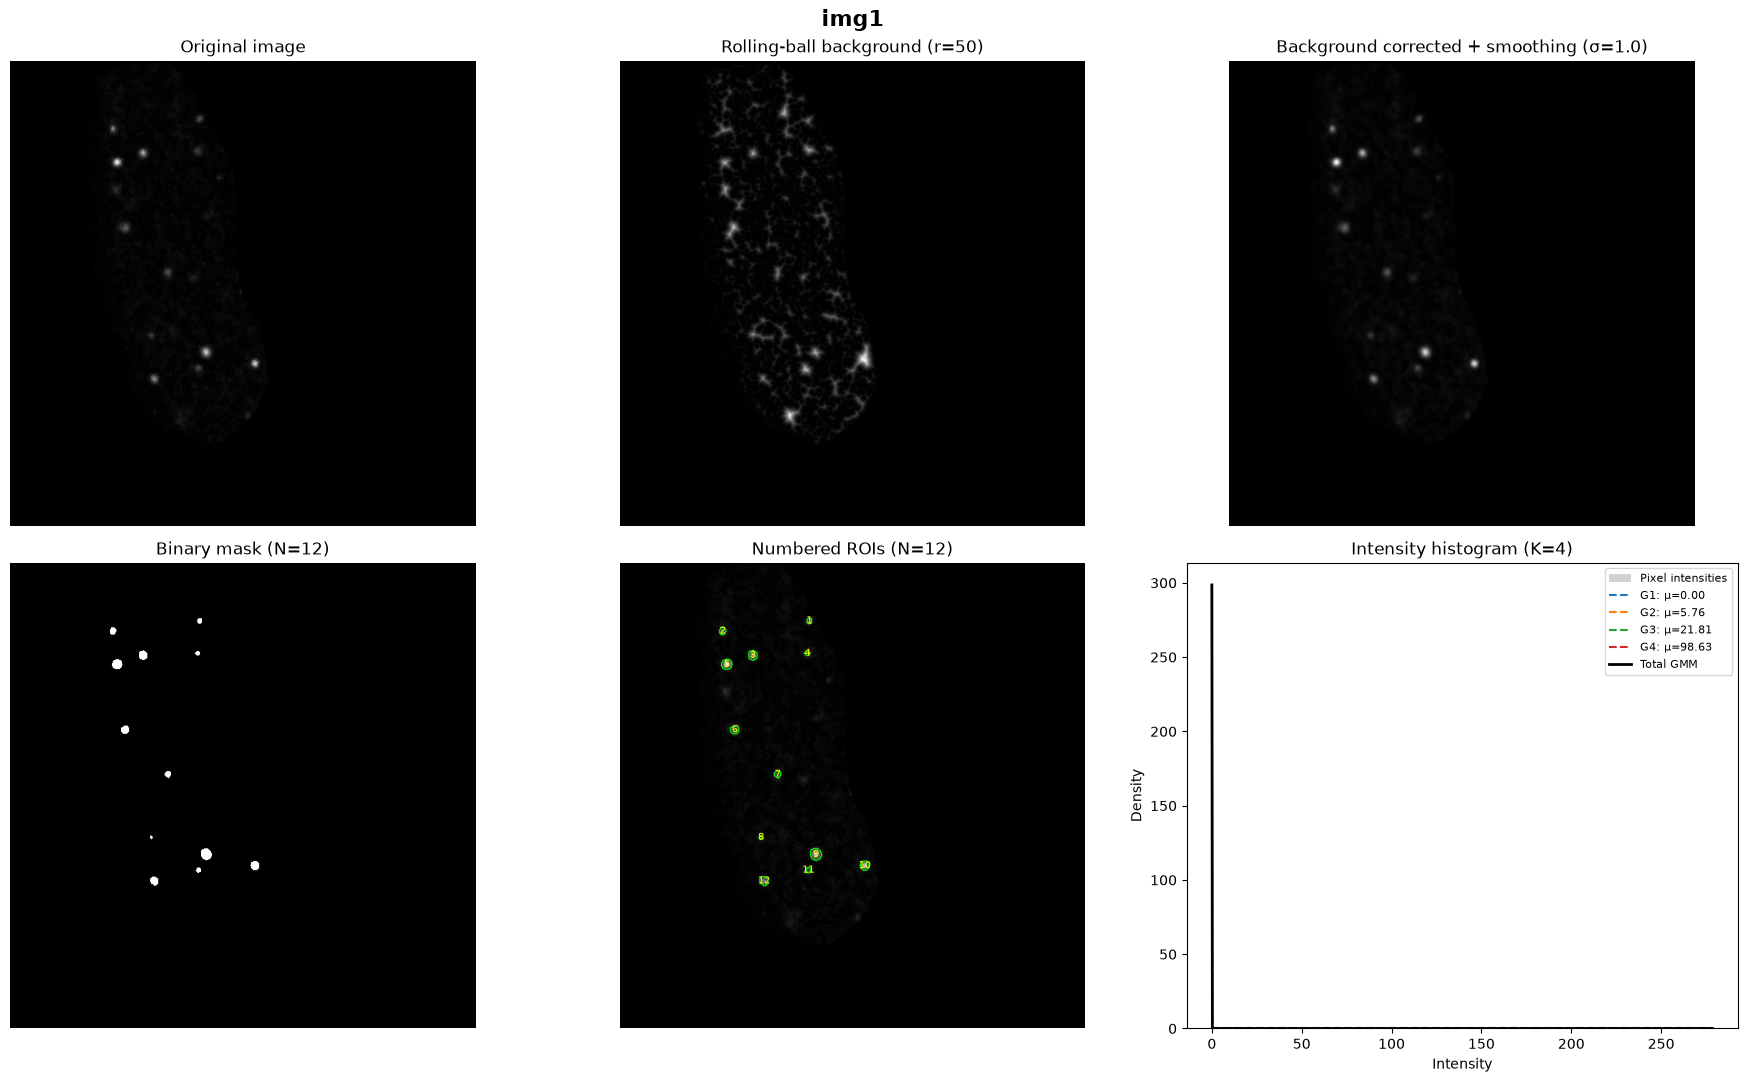


Processing: img2.tif


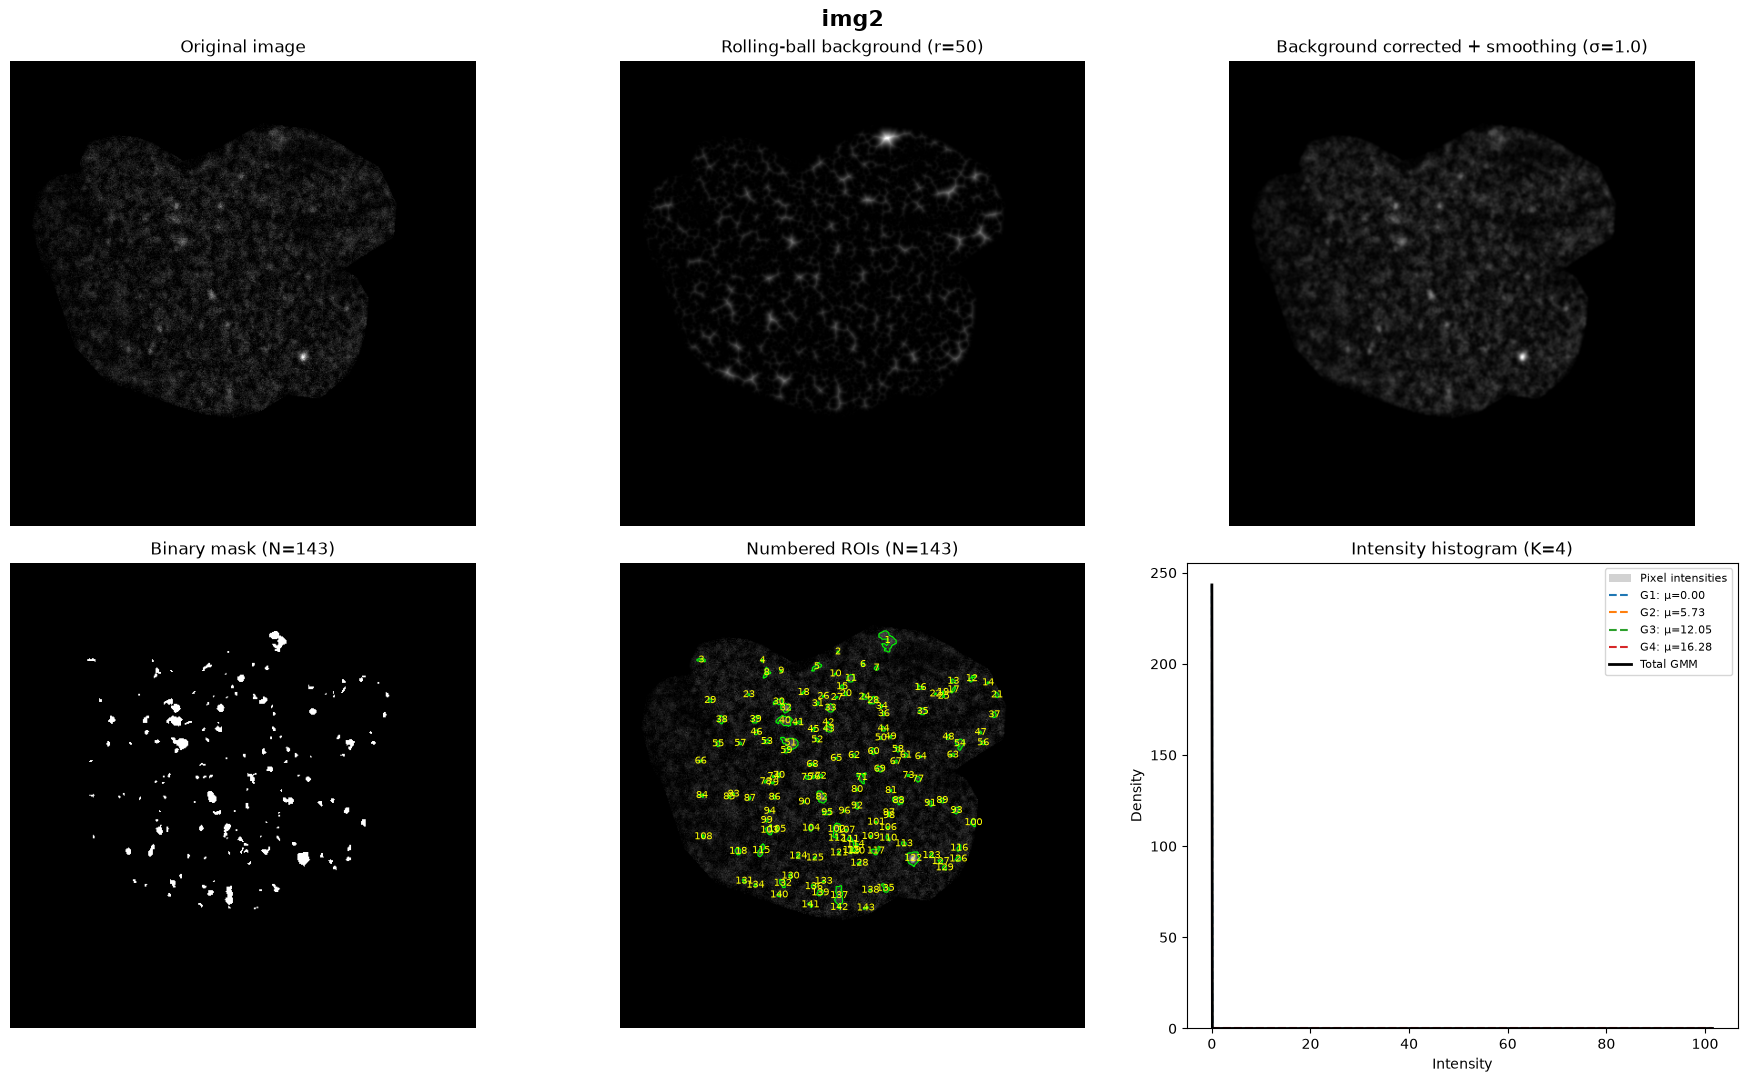


Processing: img3.tif


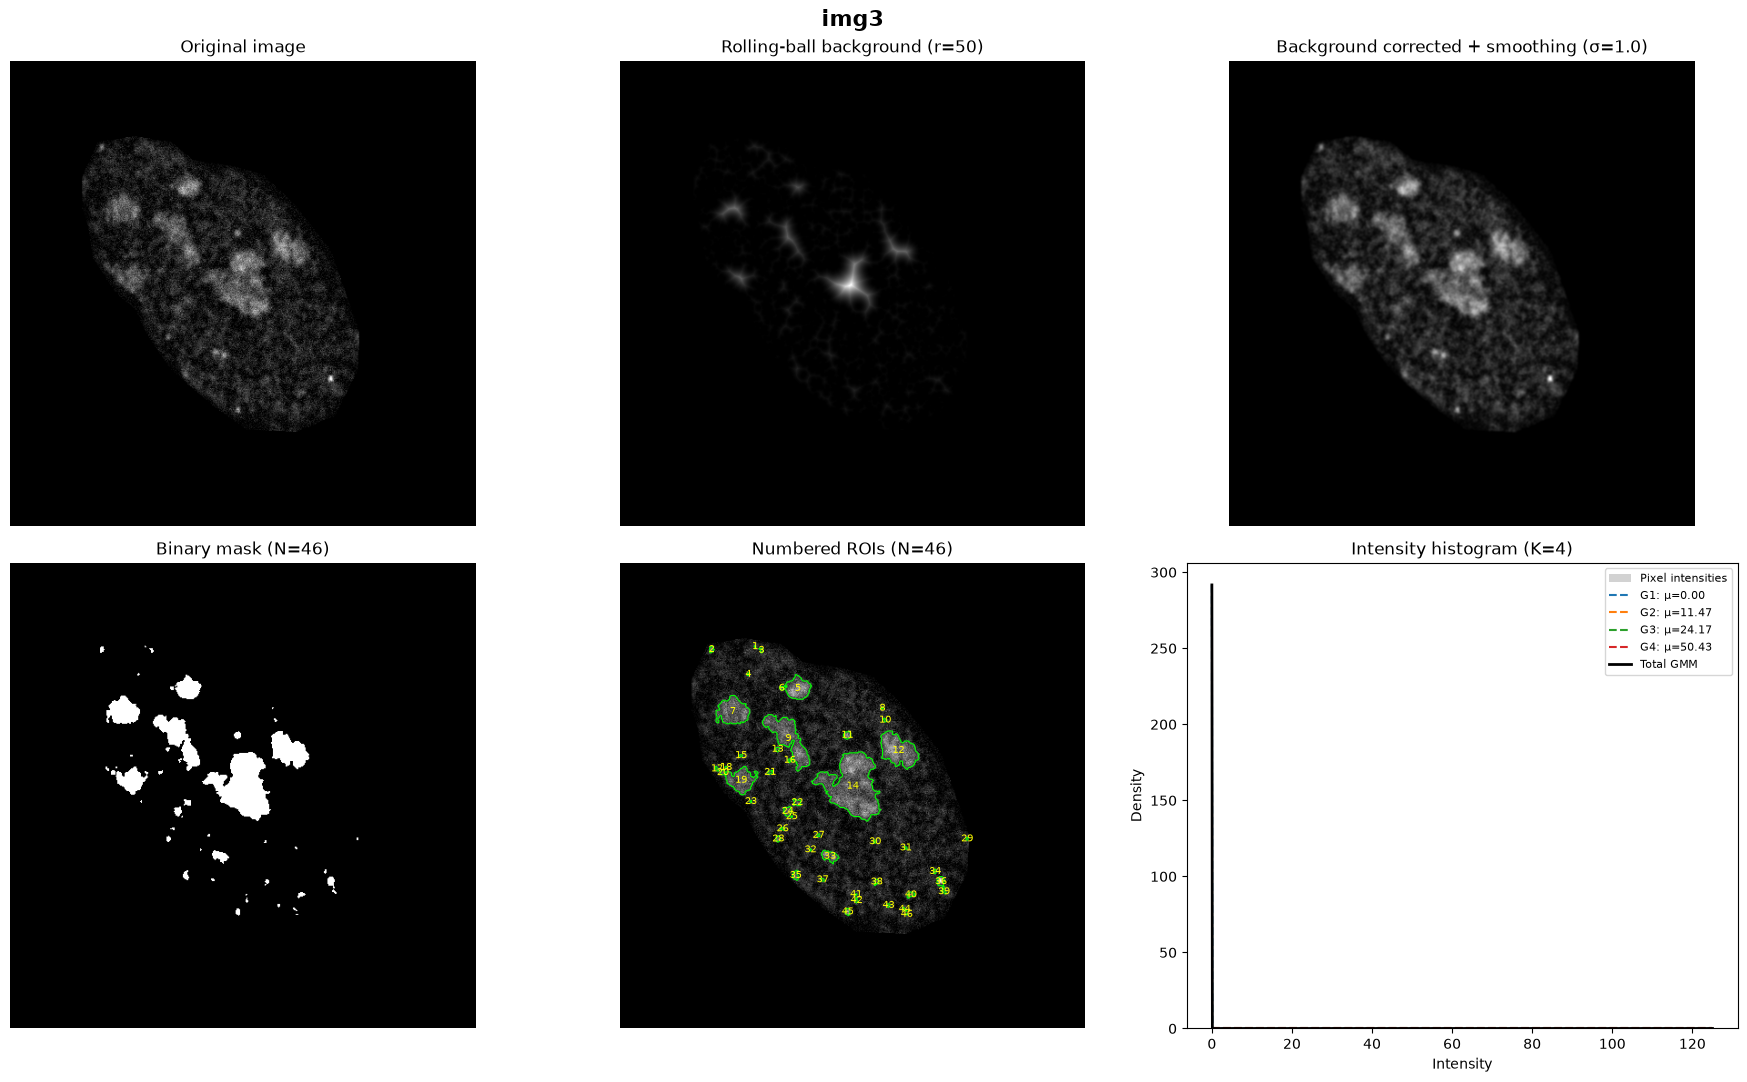


Processing: img4.tif


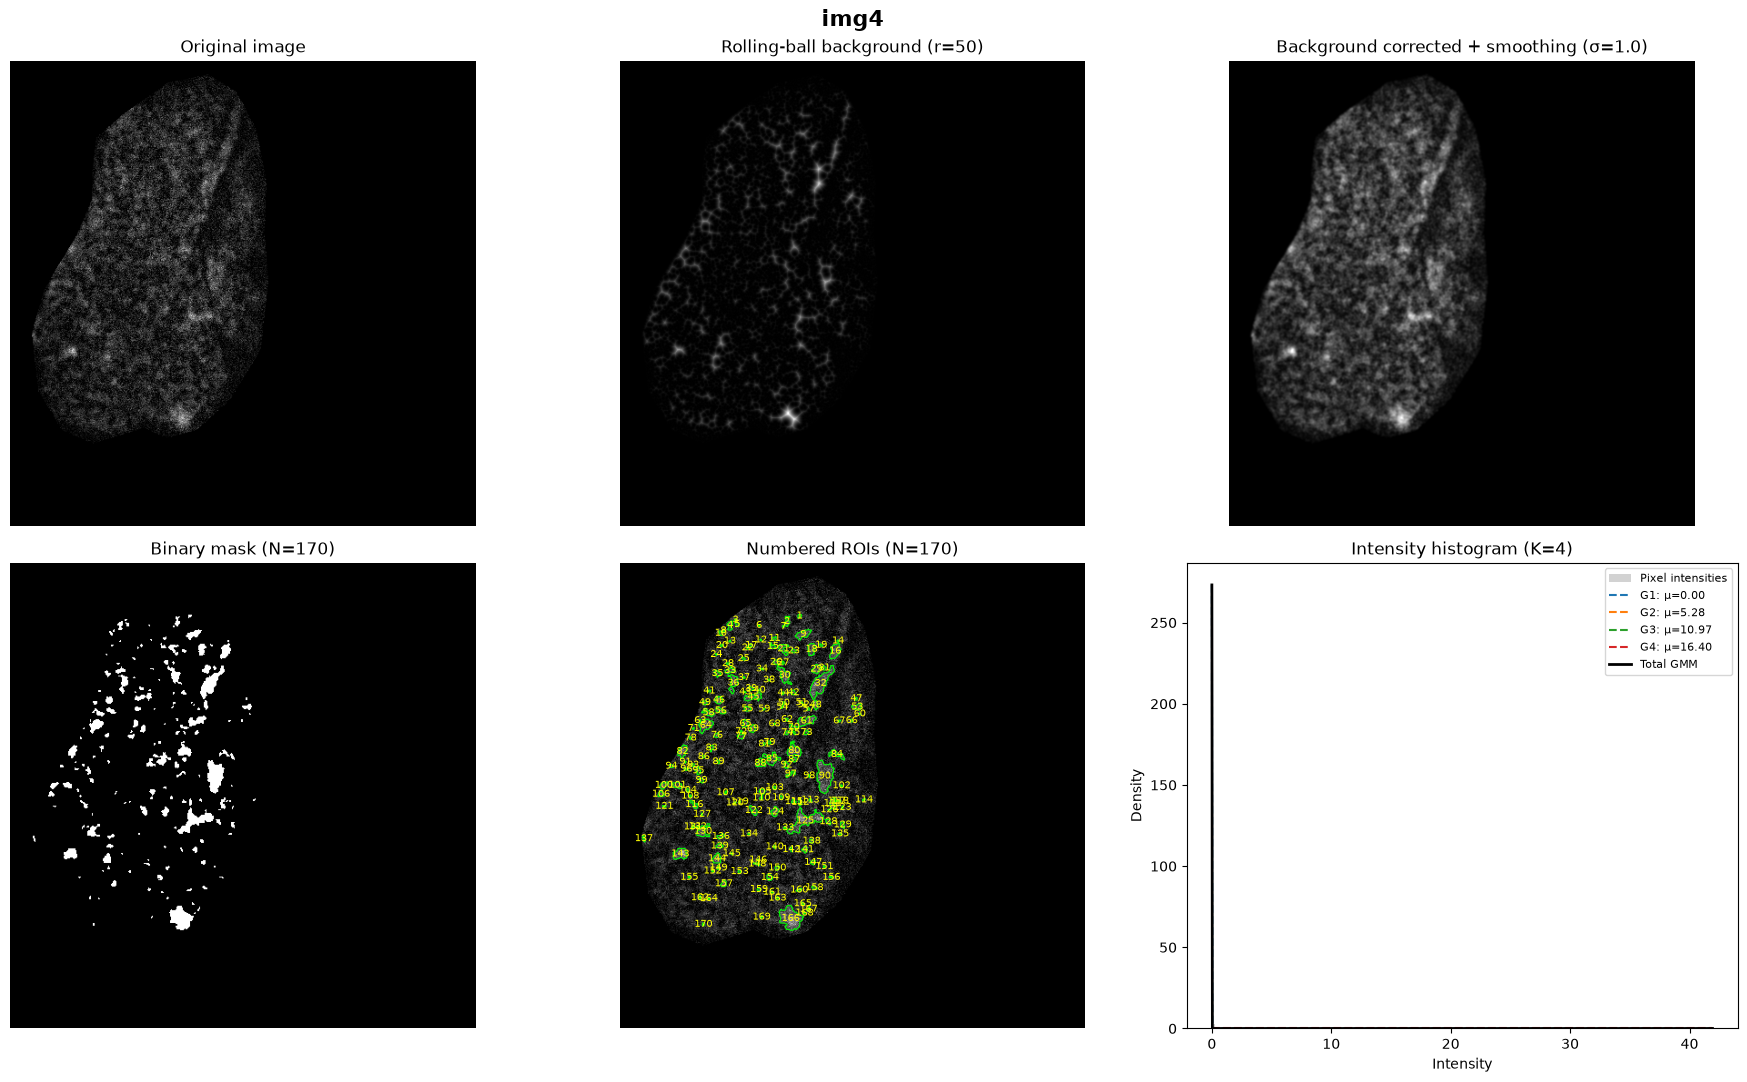

,image,n_components,n_rois,total_area_px,area_fraction
0,img1.tif,4,12,696,0.002655
1,img2.tif,4,143,3226,0.012306
2,img3.tif,4,46,8107,0.030926
3,img4.tif,4,170,5586,0.021309


In [5]:
image_paths = sorted(
    list(IMAGE_FOLDER.glob("*.tif")) +
    list(IMAGE_FOLDER.glob("*.tiff")) +
    list(IMAGE_FOLDER.glob("*.TIF")) +
    list(IMAGE_FOLDER.glob("*.TIFF"))
)

if len(image_paths) != 4:
    raise ValueError(
        f"Expected 4 TIFF images, found {len(image_paths)}"
    )

all_roi_tables = []
summary = []

for image_path in image_paths:

    print(f"\nProcessing: {image_path.name}")

    results = process_image(image_path)

    name = image_path.stem

    # Plot 6 panels
    plot_results(
        results,
        image_name=name,
        save_path=OUTPUT_FOLDER / f"{name}_analysis.png"
    )

    # Save binary mask
    io.imsave(
        OUTPUT_FOLDER / f"{name}_mask.tif",
        results["mask"].astype(np.uint8) * 255,
        check_contrast=False
    )

    # Save labeled ROIs
    io.imsave(
        OUTPUT_FOLDER / f"{name}_labels.tif",
        results["labels"].astype(np.int32),
        check_contrast=False
    )

    # Save ROI measurements
    roi_df = results["roi_df"]

    roi_df.to_csv(
        OUTPUT_FOLDER / f"{name}_ROIs.csv",
        index=False
    )

    all_roi_tables.append(roi_df)

    summary.append({
        "image": image_path.name,
        "n_components": N_COMPONENTS,
        "n_rois": int(results["labels"].max()),
        "total_area_px": int(results["mask"].sum()),
        "area_fraction": float(results["mask"].mean())
    })

# Combine all ROI measurements
combined_df = pd.concat(
    all_roi_tables,
    ignore_index=True
)

combined_df.to_csv(
    OUTPUT_FOLDER / "all_ROIs.csv",
    index=False
)

summary_df = pd.DataFrame(summary)

summary_df.to_csv(
    OUTPUT_FOLDER / "summary.csv",
    index=False
)

display(summary_df)